In [2]:
import pandas as pd
import numpy as np

import os
import re
import sys
import csv

HERE = os.getcwd()

from tree import LabelTree




In [3]:

def create_tree(df_path, output_json):


    """Complete NextBrain tree: every row of the ontology is a level-5 leaf.

    level 1  L1_tissue      one independent principal color per tissue class
    level 2  L2_division
    level 3  L3_structure
    level 4  L4_subregion
    level 5  leaf_name      labels = [allen_id]

    Unlike _build_nextbrain_tree.py, nothing is collapsed: repeated names (Thalamus/Thalamus) and
    single-child chains are kept, and whole-structure rows ('unassigned') are leaves like any other.
    Labels are only on the leaves.
    """



    # ONTOLOGY_CSV = os.path.join(HERE, 'data', 'inputs', 'nextbrain_ontology_v1.csv')
    # output_json = os.path.join(HERE, 'data', 'outputs', 'nextbrain_complete_tree.json')

    LEVEL_COLS = ['L1_tissue', 'L2_division', 'L3_structure', 'L4_subregion']
    NULL_TISSUES = {'Background'}

    # ---- Random jitter (illustrative; WP1 will estimate them) ----------------------------------------
    L1_WR = dict(wr_mu=4, wr_sigma=0.5)
    GROUP_WR = dict(wr_mu=5, wr_sigma=0.5)
    LEAF_WR = dict(wr_mu=3, wr_sigma=0.5)

    # ---- r_max of L2/L3 nodes (the table only has L4 and leaves) --------------------------------------
    # Illustrative, taken from the SynthSeg tree where the structure exists there. Set on the node where the
    # structure splits from its siblings; nodes not listed get the coarsest r_max of their children (a node
    # that is the only child of its parent never changes the label groups, so its value does not matter).
    GROUP_R_MAX = {
        'thalamus_l2': 3.5,
        'hypothalamus_l2': 1.5,
        'subthalamus_l2': 1.5,
        'basal_ganglia_l2': 3.5,
        'basal_forebrain_l2': 1.0,
        'caudate_l3': 2.0,
        'putamen_l3': 2.0,
        'pallidum_l3': 2.0,
        'accumbens_area_l3': 1.2,
        'cerebral_cortex_l2': 4.0,
        'amygdala_l2': 2.0,
        'hippocampal_formation_l2': 2.0,
        'cerebral_white_matter_l2': 4.0,
        'optic_pathway_l2': 1.5,
        'brain_stem_l3': 4.0,
        'substantia_nigra_l3': {'default': 1.0, 'T1': 0.0},
        'cerebellar_cortex_l2': 4.0,
        'cerebellar_nuclei_l2': {'default': 1.0, 'T1': 0.0},
    }

    # Table has a T1w r_max and a "best contrast" r_max. The best value is used as default for every
    # contrast; T1 gets its own value. An empty T1w cell (with a best value) means "not resolvable in
    # T1w" (prior-driven / contrast-specific structures), encoded as r_max 0 for T1.
    T1_KEY = 'T1'
    T1_MISSING = 0.0


    def snake(s):
        return re.sub(r'[^0-9a-z]+', '_', s.lower()).strip('_')


    def _float(s):
        s = (s or '').strip()
        return float(s) if s else None


    def table_r_max(t1w, best):
        t1w, best = _float(t1w), _float(best)
        if best is None:
            return None if t1w is None else t1w
        t1 = T1_MISSING if t1w is None else t1w
        return best if t1 == best else {'default': best, T1_KEY: t1}


    def _combine(rs, op):
        """Per-contrast max / min of r_max values (None = always visible, ignored)."""
        rs = [r for r in rs if r is not None]
        if not rs:
            return None
        keys = {k for r in rs if isinstance(r, dict) for k in r} | {'default'}
        get = lambda r, k: r if not isinstance(r, dict) else r.get(k, r['default'])
        out = {k: op(get(r, k) for r in rs) for k in keys}
        return out['default'] if len(set(out.values())) == 1 else out


    class _N(object):
        def __init__(self, key, level, leaf=False):
            self.key, self.level, self.leaf = key, level, leaf
            self.children, self.labels = [], []
            self.r_max = None
            self.description = ''


    def read_rows(path):
        with open(path, newline='') as f:
            return list(csv.DictReader(f))


    def build(rows):
        """Groups are named '<name>_l<level>' (the same name is used at several levels, e.g. Thalamus);
        leaves keep the snake_case leaf_name."""
        root = _N('root', 0)
        groups = {(): root}
        for row in rows:
            path = [row[c].strip() for c in LEVEL_COLS]
            if not all(path):
                raise ValueError(f'Row {row["allen_id"]} ({row["leaf_name"]}) has an empty level: {path}')
            for level in range(1, 5):
                key = tuple(path[:level])
                if key not in groups:
                    node = _N(f'{snake(path[level - 1])}_l{level}', level)
                    node.tissue = path[0]
                    groups[key[:-1]].children.append(node)
                    groups[key] = node
            l4 = groups[tuple(path)]
            r = table_r_max(row['L4_r_max_T1w_mm'], row['L4_r_max_best_mm'])
            if l4.r_max is not None and r != l4.r_max:
                raise ValueError(f'{l4.key}: inconsistent L4 r_max ({l4.r_max} vs {r})')
            l4.r_max = r

            leaf = _N(snake(row['leaf_name']), 5, leaf=True)
            leaf.labels = [int(row['allen_id'])]
            leaf.r_max = _float(row['L5_r_max_best_mm'])
            leaf.description = ', '.join(row[c] for c in ('functional_class', 'layer', 'long_axis') if row[c])
            l4.children.append(leaf)
        return root


    def walk(node):
        yield node
        for c in node.children:
            yield from walk(c)


    def fill_r_max(node, GROUP_R_MAX):
        """L2/L3: GROUP_R_MAX, else coarsest child. L4: table, else coarsest child. Leaves are clamped to
        the parent (they can never be seen beyond its limit)."""
        for c in node.children:
            fill_r_max(c, GROUP_R_MAX)
        if 2 <= node.level <= 4:
            if node.key in GROUP_R_MAX:
                node.r_max = GROUP_R_MAX[node.key]
            elif node.r_max is None:
                node.r_max = _combine([c.r_max for c in node.children], max)
        for c in node.children:
            if c.leaf:
                c.r_max = _combine([c.r_max, node.r_max], min) if node.r_max is not None else c.r_max


    def to_label_tree(root):
        tissues = [c.tissue for c in root.children if c.tissue not in NULL_TISSUES]
        t = LabelTree.new(colors=tissues, contrasts=['T1', 'T2', 'FLAIR', 'PD'], version='nextbrain-complete-0.1',
                        description='Complete NextBrain tree from nextbrain_ontology_v1.csv: L1-L4 columns are '
                                    'levels 1-4, leaf_name is level 5 with label = allen_id. Each level-1 tissue is '
                                    'an independent color. Left and right share a node. Jitters and L2/L3 r_max '
                                    'are illustrative; L4 and leaf r_max come from the table '
                                    '(best contrast = default, T1 = T1w).')

        def add(n, parent):
            if n.level == 1:
                if n.tissue in NULL_TISSUES:
                    kw = dict(null=True)
                else:
                    kw = dict(L1_WR, w_mu=[float(c == n.tissue) for c in tissues])
            else:
                kw = dict(LEAF_WR if n.leaf else GROUP_WR, r_max=n.r_max)
            t.add_node(n.key, parent, labels=n.labels, description=n.description, **kw)
            for c in n.children:
                add(c, n.key)

        for c in root.children:
            add(c, 'root')
        return t


    rows = read_rows(df_path)
    # convert df to to list of string
    # rows = df.astype(str).to_dict(orient='records')
    root = build(rows)
    keys = [n.key for n in walk(root)]
    dup = sorted({k for k in keys if keys.count(k) > 1})
    if dup:
        raise ValueError(f'Duplicated node names: {dup}')
    # A part only contains some of the structures: keep the GROUP_R_MAX entries present in this tree
    GROUP_R_MAX = {k: v for k, v in GROUP_R_MAX.items() if k in keys}
    fill_r_max(root, GROUP_R_MAX)
    t = to_label_tree(root)

    t.validate()
    os.makedirs(os.path.dirname(output_json), exist_ok=True)
    t.to_json(output_json)
    print(len(t.nodes), 'nodes,', len(t.leaves()), 'leaves,', len(t.label_to_node), 'labels,',
        len(t.colors), 'colors:', t.colors)


In [4]:
df = pd.read_csv("/home/agustin/phd/synthseg_nextbrain/project/dev/wp1/create_nextbraintree/data/inputs/nextbrain_ontology_v1.csv")
L1_tissue = np.unique(df["L1_tissue"].values)
print("L1_tissue:", L1_tissue)

output_dir = os.path.join(HERE, "data", "outputs", "nextbrain_tree_v1_per_parts")
for tissue in L1_tissue:
    _df = df[df["L1_tissue"] == tissue]

    # conver tissue to lower case, remove special characters and replace spaces with underscores
    tissue = re.sub(r'[^a-z0-9]+', '_', tissue.lower()).strip('_')

    if not os.path.exists(output_dir):
        os.makedirs(output_dir)

    #save temporary csv file for the tissue
    temp_path = os.path.join(output_dir, f"nextbrain_ontology_{tissue}.csv")
    _df.to_csv(temp_path, index=False)
    create_tree(temp_path, os.path.join(output_dir, f"nextbrain_tree_{tissue}.json"))

    # remove temporary csv file
    os.remove(temp_path)
    
    


L1_tissue: ['Background' 'Brainstem' 'CSF / ventricles' 'Cerebellar GM'
 'Cerebellar WM' 'Cerebral GM' 'Cerebral WM' 'Deep GM' 'Other']
6 nodes, 1 leaves, 1 labels, 0 colors: []
100 nodes, 90 leaves, 90 labels, 1 colors: ['Brainstem']
8 nodes, 2 leaves, 2 labels, 1 colors: ['CSF / ventricles']
15 nodes, 6 leaves, 6 labels, 1 colors: ['Cerebellar GM']
7 nodes, 2 leaves, 2 labels, 1 colors: ['Cerebellar WM']
135 nodes, 105 leaves, 105 labels, 1 colors: ['Cerebral GM']
24 nodes, 8 leaves, 8 labels, 1 colors: ['Cerebral WM']
174 nodes, 120 leaves, 120 labels, 1 colors: ['Deep GM']
6 nodes, 1 leaves, 1 labels, 1 colors: ['Other']


saved /home/agustin/phd/synthseg_nextbrain/project/dev/wp1/create_nextbraintree/data/outputs/nextbrain_tree_v1_per_parts/nextbrain_tree_background_0.1mm.png
saved /home/agustin/phd/synthseg_nextbrain/project/dev/wp1/create_nextbraintree/data/outputs/nextbrain_tree_v1_per_parts/nextbrain_tree_brainstem_0.1mm.png
saved /home/agustin/phd/synthseg_nextbrain/project/dev/wp1/create_nextbraintree/data/outputs/nextbrain_tree_v1_per_parts/nextbrain_tree_cerebellar_gm_0.1mm.png
saved /home/agustin/phd/synthseg_nextbrain/project/dev/wp1/create_nextbraintree/data/outputs/nextbrain_tree_v1_per_parts/nextbrain_tree_cerebellar_wm_0.1mm.png
saved /home/agustin/phd/synthseg_nextbrain/project/dev/wp1/create_nextbraintree/data/outputs/nextbrain_tree_v1_per_parts/nextbrain_tree_cerebral_gm_0.1mm.png
saved /home/agustin/phd/synthseg_nextbrain/project/dev/wp1/create_nextbraintree/data/outputs/nextbrain_tree_v1_per_parts/nextbrain_tree_cerebral_wm_0.1mm.png
saved /home/agustin/phd/synthseg_nextbrain/project/

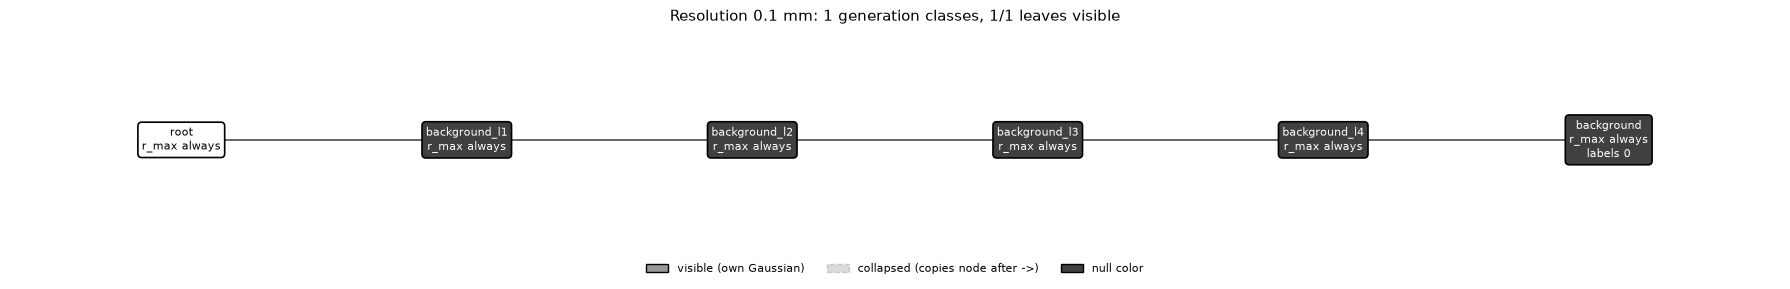

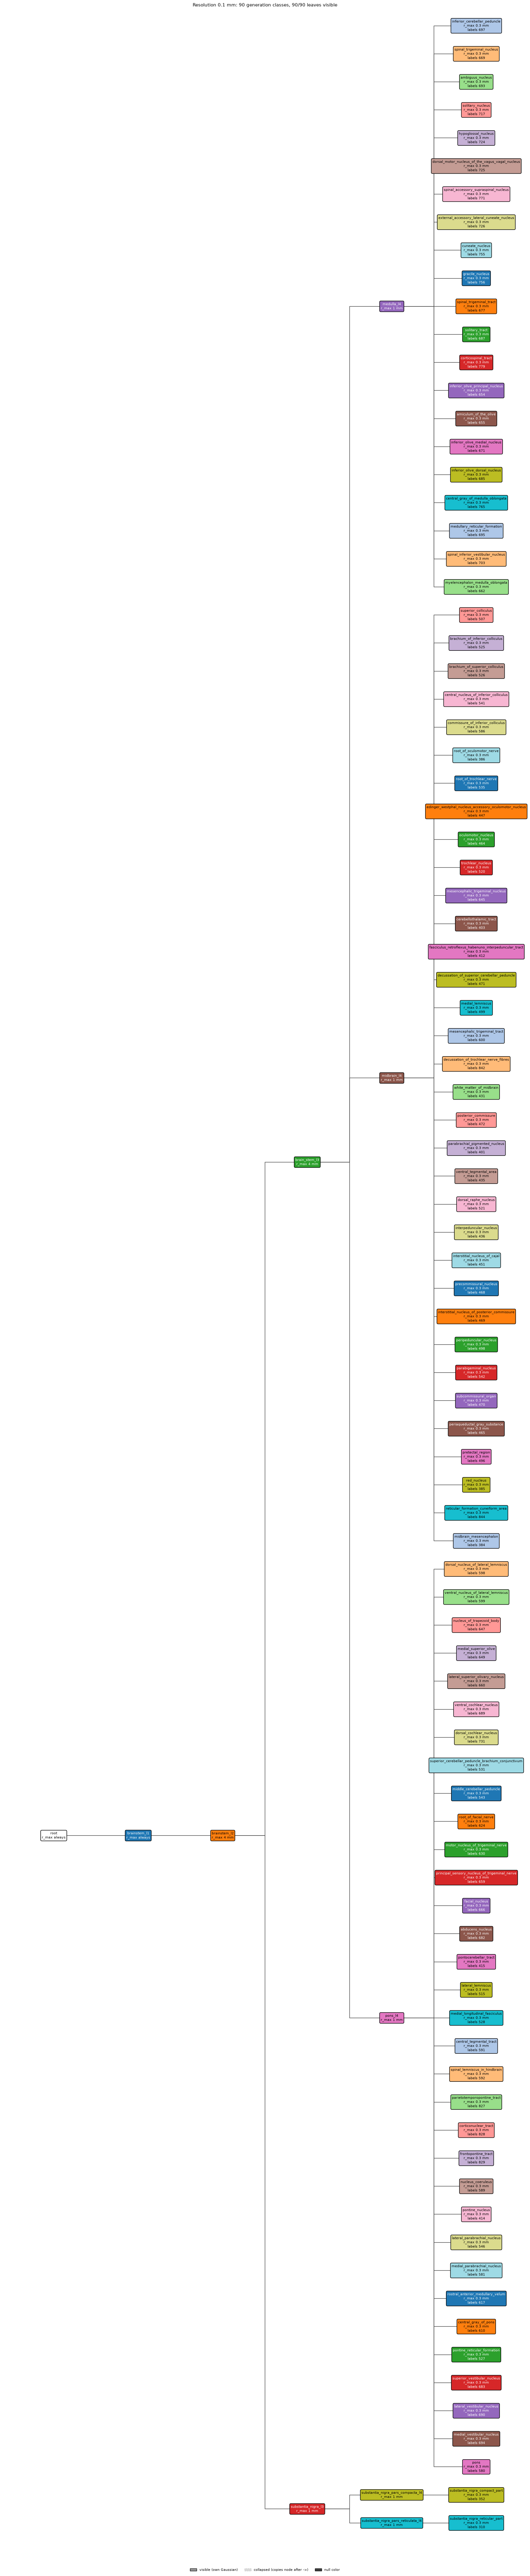

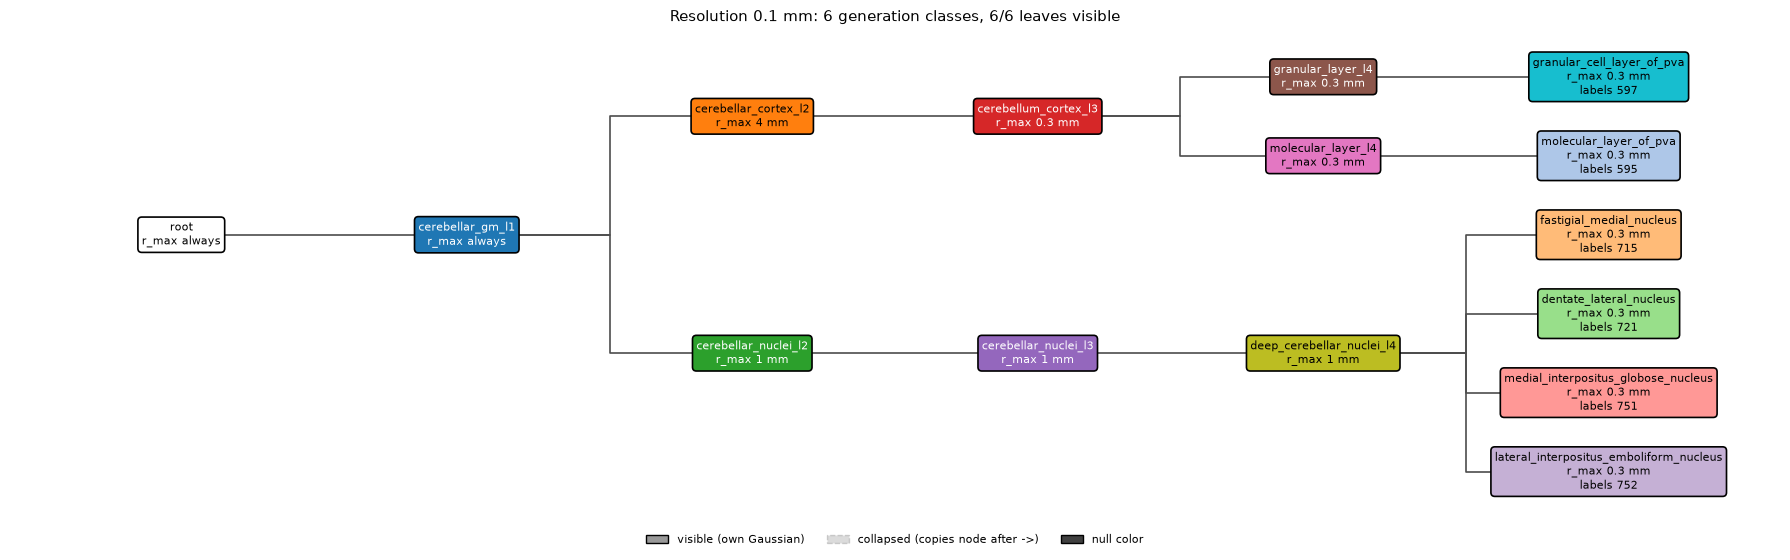

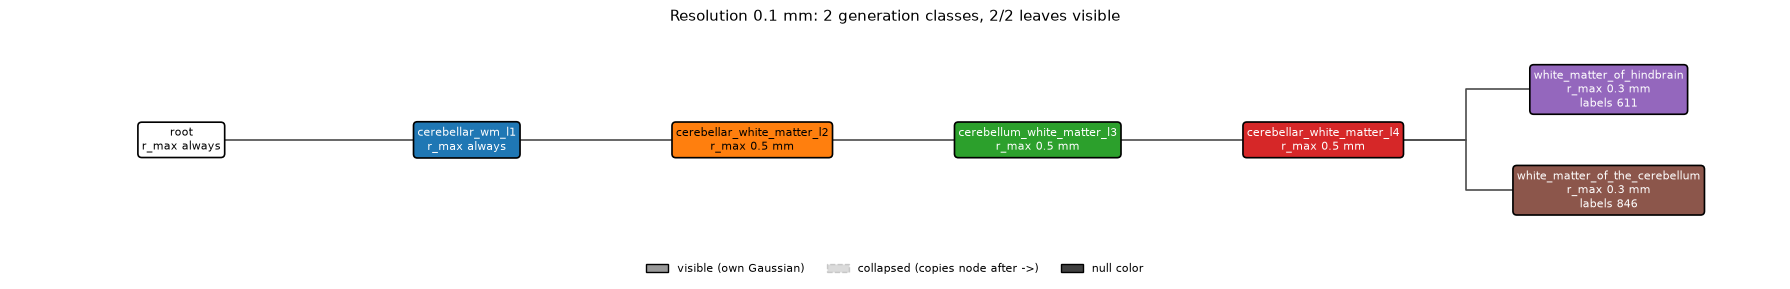

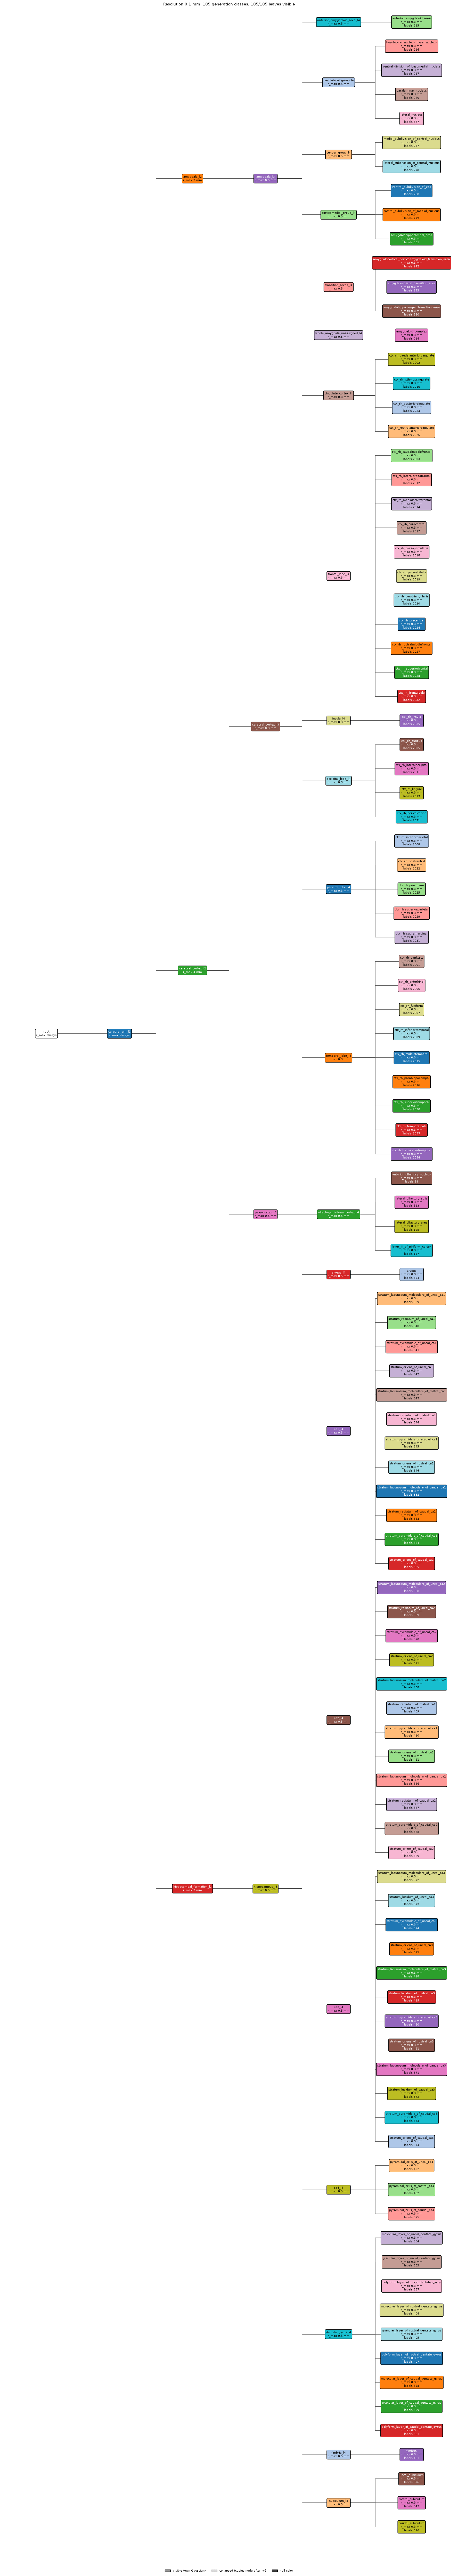

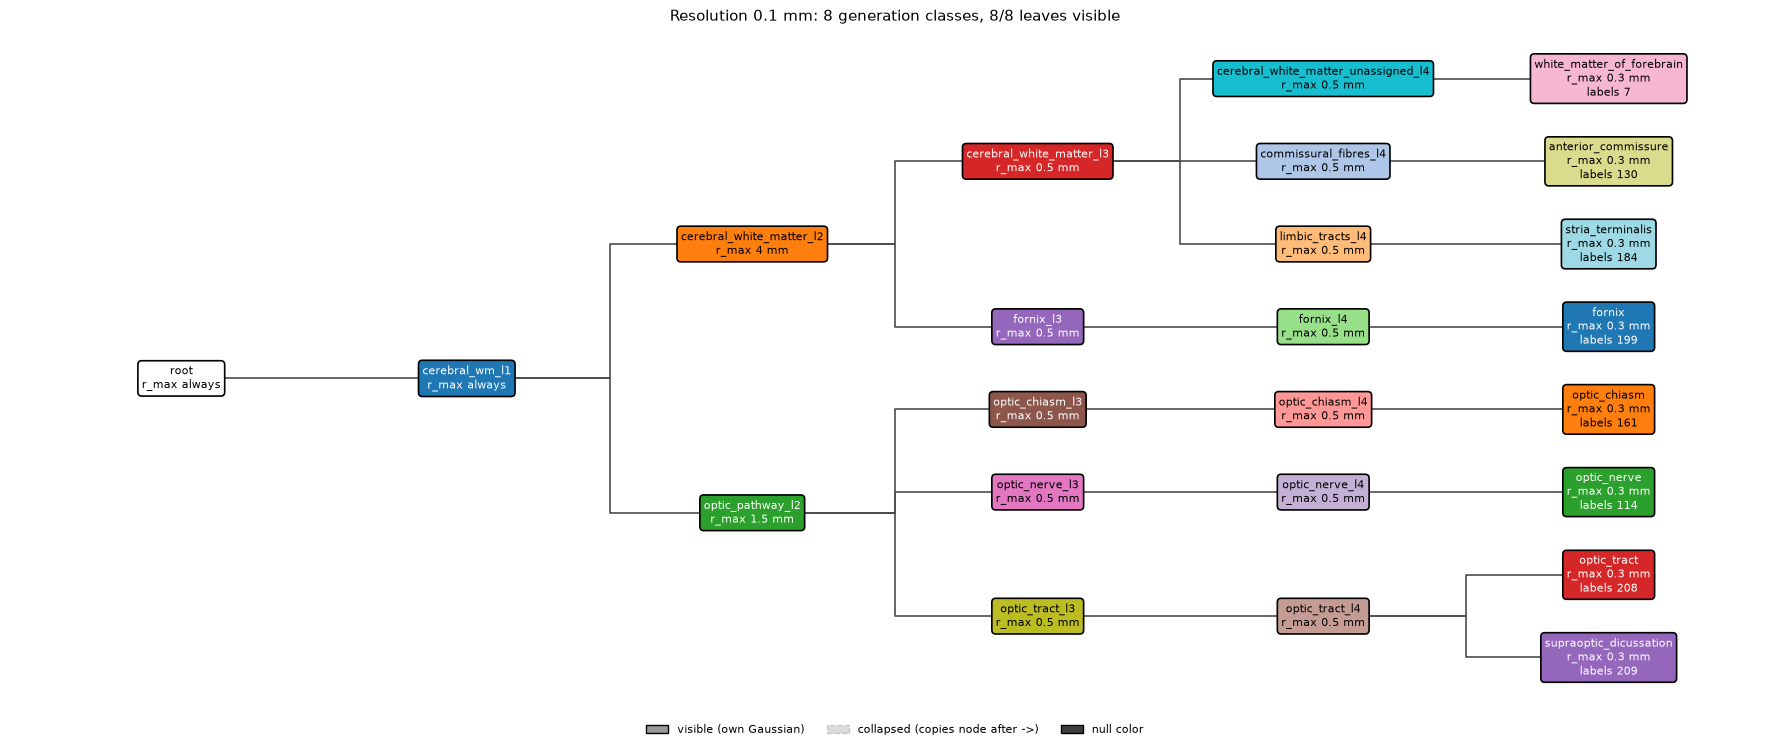

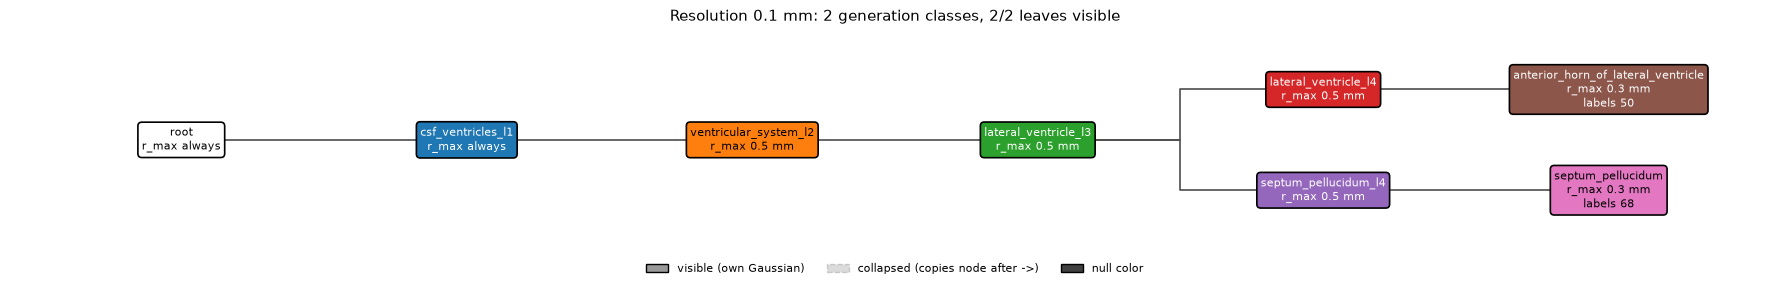



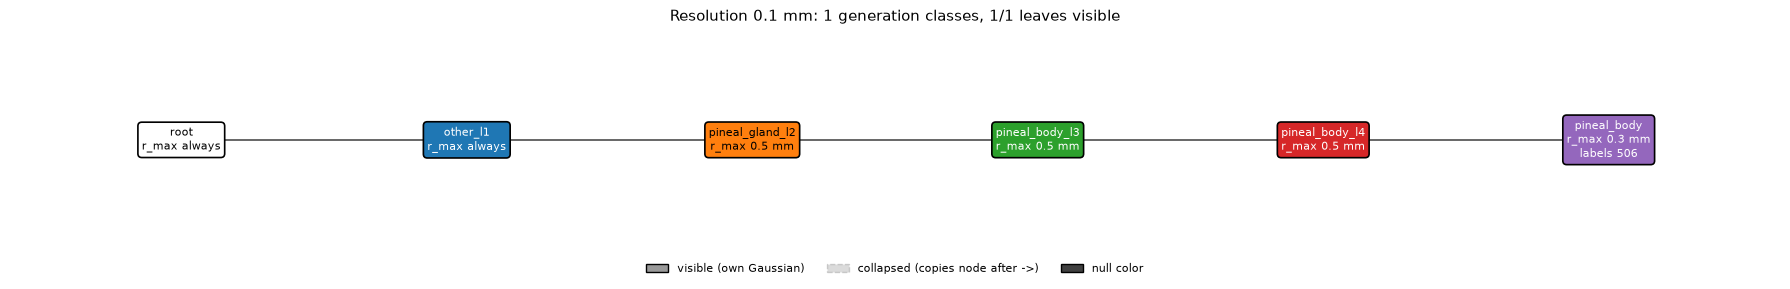

In [5]:
# plot every tree at 0.1 mm with tree_plot.py and save the images in outputs
import glob
import subprocess

import tree_plot

RESOLUTION = 0.1

for tree_json in sorted(glob.glob(os.path.join(output_dir, 'nextbrain_tree_*.json'))):
    out_png = tree_json.replace('.json', f'_{RESOLUTION}mm.png')
    #     plot_tree(
    #     tree=args.i,
    #     resolution=args.resolution,
    #     contrast=args.contrast,
    #     orientation=args.orientation,
    #     show_labels=args.show_labels,
    #     show_root=args.show_root,
    #     save=output,
    #     cmap=args.cmap,
    #     lut=args.lut
    # )

    tree_plot.plot_tree(
        tree=tree_json,
        resolution=RESOLUTION,
        contrast=None,
        orientation='horizontal',
        show_labels=True,
        show_root=True,
        save=out_png,
        cmap=None,
        lut=None
    )

    # subprocess.run([sys.executable, TREE_PLOT, '--i', tree_json, '--o', out_png,
    #                 '--resolution', str(RESOLUTION)], check=True)
    print('saved', out_png)
